<a href="https://colab.research.google.com/github/dkalchenko01/UA-Locations-NER-Deep-Learning/blob/eda-%26-validation/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA and Metric Analysis

- Perform Exploratory Data Analysis (EDA).
- Analyze the proposed target metric: discuss its strengths, weaknesses, and potential edge cases.
- Suggest complementary metrics to capture other aspects of performance.
- Propose an alternative target metric, with justification.

# Key Findings for Modeling

### 1. Test is a different domain
Long Telegram-style posts (median 264 chars, 52% emojis, 85% line breaks) vs. short train sentences (~100 chars).
- Validate on in-domain data (`labeling_sample`), not on a random train split.
- Concatenate sentences, add emoji/URL/hashtag augmentation.
- Keep `\n` and emojis as tokens

### 2. Test is small and mostly Ukrainian (~90% Ukrainian, only 477 texts)
- Train mostly on UK data plus a subsample of ru.

### 3. Leakage risks in ru
739k documents (`doc_id`) and ≥4.5% duplicate texts.
- Split by `doc_id` and deduplicate texts before splitting.

### 4. Homoglyphs in UK
Latin letters inside Cyrillic words (`Укрaїнa`).
- Normalize them in the model input.
- Take predicted strings from the original text.

### 5. Label noise
219 spans with edge whitespace, wrong boundaries (`-Франківська`), non-locations.
- Strip whitespace at span edges.
- Check hyphen boundaries before BIO conversion.
- Consider filtering noisy spans.


# Environment Setup

In [37]:
import os
import sys
import ast
import base64
import random
import subprocess

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import unicodedata
import re

In [2]:
if "google.colab" in sys.modules:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    root = "/content"
else:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    root = "/kaggle/working"

repo = "UA-Locations-NER-Deep-Learning"
branch = "eda-&-validation"
repo_dir = f"{root}/{repo}"

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

if not os.path.exists(repo_dir):
    subprocess.run(
        ["git", "clone", "-b", branch, f"https://github.com/dkalchenko01/{repo}.git", repo_dir],
        env=env, check=True
    )

print("Repository:", repo_dir)

Repository: /content/UA-Locations-NER-Deep-Learning


In [6]:
sys.path.insert(0, repo_dir)
from src.data_io import get_data_dir

ENVIRONMENT = "colab" if root == "/content" else "kaggle"

data_dir = Path(get_data_dir(ENVIRONMENT))
print("Data directory:", data_dir)

for path in sorted(data_dir.iterdir()):
    print(path.name, "DIR" if path.is_dir() else "FILE")

Data directory: /root/.cache/kagglehub/competitions/kse-ua-location-extraction-2026
README.md FILE
labeling_sample.csv FILE
ru_geo_dataset.csv FILE
test.csv FILE
uk_geo_dataset.csv FILE
uk_geo_dataset_processed_v1.parquet FILE


# Dataset Overview

##  Dataset Schema

In [7]:
for file in sorted(data_dir.glob("*.csv")):
    print(f"{file.name}")
    print("Columns:", pd.read_csv(file, nrows=0).columns.tolist(), "\n")

file = data_dir / "uk_geo_dataset_processed_v1.parquet"
print(f"{file.name}")
print(pq.ParquetFile(file).schema_arrow, "\n")

labeling_sample.csv
Columns: ['text', 'locations', 'loc_markers'] 

ru_geo_dataset.csv
Columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'doc_id', 'sent_id'] 

test.csv
Columns: ['text_id', 'text', 'locations'] 

uk_geo_dataset.csv
Columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'is_valid'] 

uk_geo_dataset_processed_v1.parquet
tokens: extension<arrow.json>
labels: extension<arrow.json>
is_valid: int64
-- schema metadata --
pandas: '{"column_indexes": [{"field_name": null, "metadata": null, "name' + 618 



The Ukrainian and Russian CSV files contain labeled location spans, but have different additional columns. `labeling_sample.csv` provides annotation examples, while `test.csv` is used for Kaggle predictions. The processed Parquet file requires further verification.

In [8]:
previews = {}
for name in ["labeling_sample.csv", "uk_geo_dataset.csv", "ru_geo_dataset.csv", "test.csv"]:
    print(f"\n{name}")
    previews[name] = pd.read_csv(data_dir / name, nrows=2)
    display(previews[name].T)

print("\nuk_geo_dataset_processed_v1.parquet")
parquet = pq.ParquetFile(data_dir / "uk_geo_dataset_processed_v1.parquet")
display(next(parquet.iter_batches(batch_size=2)).to_pandas().T)


labeling_sample.csv


,0,1
text,-261.310,"Проспект Бандери стоїть, як і пів міста… довго..."
locations,[],['Проспект Бандери']
loc_markers,[],"[(0, 16)]"



uk_geo_dataset.csv


,0,1
text,"Чим довше мають скачки тиску гіпертензією, тим...","А поки що починали цвісти троянди, випускники ..."
loc_markers,[],[]
org_markers,[],[]
per_markers,[],"[(114, 131)]"
is_valid,0,0



ru_geo_dataset.csv


,0,1
text,Вице-премьер по социальным вопросам Татьяна Го...,"По словам Голиковой, чаще всего онкологические..."
loc_markers,"[(82, 88)]","[(89, 98), (100, 108), (110, 118), (121, 139),..."
org_markers,"[(149, 160)]",[]
per_markers,"[(36, 52)]","[(10, 19)]"
doc_id,0,0
sent_id,0,1



test.csv


,0,1
text_id,0,1
text,"❗️Кількість поранених зросла до трьох, – Кличк...","🥤В Києві за 91,13 млн гривень починаються робо..."
locations,[],[]



uk_geo_dataset_processed_v1.parquet


,0,1
tokens,"[""\u0427\u0438\u043c"",""\u0434\u043e\u0432\u044...","[""\u0410"",""\u043f\u043e\u043a\u0438"",""\u0449\u..."
labels,"[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""..."
is_valid,0,0


In [9]:
df = previews["ru_geo_dataset.csv"]
text = df.loc[0, "text"]
markers = ast.literal_eval(df.loc[0, "loc_markers"])

print("TEXT:", text)
print("\nLOCATIONS:", [text[start:end] for start, end in markers])
print("MARKERS:", markers)

TEXT: Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высокая смертность от рака, сообщает РИА Новости.

LOCATIONS: ['России']
MARKERS: [(82, 88)]


In [10]:
for chunk in pd.read_csv(data_dir / "uk_geo_dataset.csv", chunksize=1000):
    rows = chunk[chunk["loc_markers"].fillna("[]") != "[]"]
    if not rows.empty:
        row = rows.iloc[0]
        break

text = row["text"]
markers = ast.literal_eval(row["loc_markers"])

print("TEXT:", text)
print("\nLOCATIONS:", [text[start:end] for start, end in markers])
print("MARKERS:", markers)
print("IS_VALID:", row["is_valid"])

TEXT: Подібні розіграші проводили в Великій Британії.

LOCATIONS: ['Великій Британії']
MARKERS: [(30, 46)]
IS_VALID: 0


Location annotations use character offsets `[start, end)`. This format works consistently in the inspected Ukrainian and ru examples. The `is_valid` column indicates the original validation split, not annotation quality.

## Shared Streaming Aggregates


In [11]:
from src.eda_scan import scan_dataset

In [12]:
scans = {
    "UK": scan_dataset(data_dir / "uk_geo_dataset.csv", check_uk_limit=True),
    "ru": scan_dataset(data_dir / "ru_geo_dataset.csv", include_documents=True)
}
coverage = pd.DataFrame([result["coverage"] for result in scans.values()])
lengths = {label: result["text_lengths"] for label, result in scans.items()}

## Dataset Size and Location Coverage

In [13]:
display(coverage)

,dataset,total_texts,with_locations,without_locations,location_pct
0,uk_geo_dataset.csv,1010000,233421,776579,23.11
1,ru_geo_dataset.csv,8028840,2464436,5564404,30.69


The ru dataset is almost 8 times larger than the Ukrainian one. Locations are annotated in 30.69% of ru texts and 23.11% of Ukrainian texts. Most texts in both datasets have no annotated locations.

## Text Length Distribution

Using a random sample of 50,000 texts from each dataset

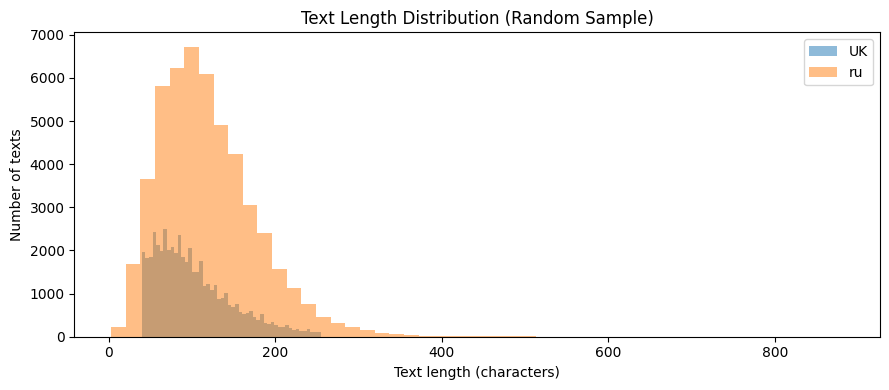

,median,p95,p99,max
UK,92.0,197.0,238.0,255.0
ru,110.0,227.0,301.0,882.0


In [15]:
fig, ax = plt.subplots(figsize=(9, 4))

for label, values in lengths.items():
    ax.hist(values, bins=50, alpha=0.5, label=label)

ax.set_title("Text Length Distribution (Random Sample)")
ax.set_xlabel("Text length (characters)")
ax.set_ylabel("Number of texts")
ax.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    label: {
        "median": values.median(),
        "p95": values.quantile(0.95),
        "p99": values.quantile(0.99),
        "max": values.max()
    }
    for label, values in lengths.items()
}).T.round(1))

Most texts are short. In random samples of 50,000 texts, the median length is 92 characters for Ukrainian and 110 for ru. ru texts tend to be longer. The Ukrainian dataset may have a 255-character limit.

In [16]:
total, max_length, at_255, over_255 = scans["UK"]["uk_limit"]
print("Texts checked:", total)
print("Maximum length:", max_length)
print("Exactly 255 characters:", at_255)
print("Longer than 255:", over_255)

Texts checked: 1010000
Maximum length: 255
Exactly 255 characters: 519
Longer than 255: 0


All 1,010,000 Ukrainian texts are at most 255 characters long. Only 519 texts reach this limit. Token lengths still need to be analyzed separately.

# Location Annotation Quality

### Character Offset Validation

In [17]:
for label, result in scans.items():
    total_spans, invalid_spans, examples = result["offsets"]
    print(label)
    print(f"Total spans: {total_spans:,}")
    print(f"Invalid spans: {invalid_spans:,}")
    print(f"Invalid rate: {invalid_spans / total_spans:.4%}" if total_spans else "No spans found")
    print("Examples:", examples)

UK
Total spans: 345,114
Invalid spans: 0
Invalid rate: 0.0000%
Examples: []
ru
Total spans: 3,708,173
Invalid spans: 0
Invalid rate: 0.0000%
Examples: []


The source run found valid offsets for all 4,053,287 examined spans. Structural validity alone does not establish annotation correctness.

### Additional properties of location annotations

- **Overlapping spans**: Identify texts containing intersecting location annotations, which may cause ambiguity during BIO label conversion.

- **Whitespace boundaries**: Detect location spans that begin or end with whitespace, indicating potentially imprecise annotation boundaries.

- **Span lengths**: Analyze the character lengths of annotated locations to identify unusually long entities and potential annotation anomalies.

These checks help assess annotation consistency before tokenization and BIO label alignment.

In [23]:
for label, result in scans.items():
    print(label, "Overlapping texts:", result["audit"]["overlap_texts"])

UK Overlapping texts: 0
ru Overlapping texts: 0


In [18]:
summary = pd.DataFrame(
    [result["audit"] for result in scans.values()], index=list(scans)
).fillna(0).astype(int)
display(summary.T)

,UK,ru
texts,1010000,8028840
spans,345114,3708173
whitespace_spans,206,13
long_spans,0,4


Whitespace boundary issues are rare: 206 spans in UK (0.060%) and 13 in ru (0.00035%). Additionally, only 4 ru spans exceed 100 characters, compared with none in UK.

Overall, the annotations appear structurally consistent. However, the whitespace cases and unusually long spans require manual inspection before deciding whether any preprocessing corrections are necessary.

### Manual Inspection of Suspicious Location Spans

In [24]:
for label, result in scans.items():
    print(f"{label} whitespace examples:")
    for example in result["whitespace_examples"]:
        print(f"Text: {example['context']}")
        print(f"Location: {example['location']!r}")
        print(f"Offsets: ({example['start']}, {example['end']})\n")

UK whitespace examples:
Text: ці беруть участь в атаках на аеропорт в [Донецьку, ]- штаб АТО Бойовики продовжують атакуват
Location: 'Донецьку, '
Offsets: (63, 73)

Text: трольних пунктів в'їзду-виїзду (КПВВ) у [Луганській області "Золоте" та ]"Щастя" на 10 листопада.
Location: 'Луганській області "Золоте" та '
Offsets: (69, 100)

Text: А до того на цьому місці стояв [Вознесенський жіночий ]монастир, в якому ігуменею була Марина, 
Location: 'Вознесенський жіночий '
Offsets: (31, 53)

Text: і 15 квітня оголошена евакуація острова [Сіте, на якому ]розташований охоплений вогнем собор Пари
Location: 'Сіте, на якому '
Offsets: (55, 70)

Text: Нагадаємо, у ніч проти 30 жовтня у [Мурманській області Росії сталася ]аварія, унаслідок якої плавучий док зато
Location: 'Мурманській області Росії сталася '
Offsets: (35, 69)

ru whitespace examples:
Text:  этом говорится в заявлении российского [лидера, показанного в эфире телеканала «Россия ]1».
Location: 'лидера, показанного в эфире телеканала «Ро

Some contain extra spaces or punctuation, while others mark text that is not a location.

In [25]:
uk_sample = scans["UK"]["span_sample"]
ru_sample = scans["ru"]["span_sample"]
print(f"UK: {len(uk_sample)} annotations")
print(f"ru: {len(ru_sample)} annotations")

UK: 100 annotations
ru: 100 annotations


In [26]:
def prepare_review(df, context=50):
    review = df.copy()
    review["context"] = review.apply(
        lambda r: r["text"][max(0, r["start"] - context):r["start"]]
        + " [" + r["location"] + "] "
        + r["text"][r["end"]:r["end"] + context],
        axis=1
    )
    review["review"] = ""
    return review[["location", "context", "review"]]

uk_review = prepare_review(uk_sample)
ru_review = prepare_review(ru_sample)

pd.set_option("display.max_colwidth", None)
print("UK — first 40 review examples")
display(uk_review.iloc[:40])
print("ru — first 30 review examples")
display(ru_review.iloc[:30][["location", "context"]])

UK — first 40 review examples


,location,context,review
0,Широкиного,На захист [Широкиного] незабаром прибуде один з найкращих українських пі,
1,Харків,травмами привезли до реанімаційного відділення в [Харків] .,
2,-Франківська,"Власник ""жужика"" з Івано [-Франківська] перетворив свій ""Запорожець"" на справжній шедевр.",
3,Новоолексіївка,"Інцидент трапився пізно ввечері 29 вересня у смт [Новоолексіївка] , але затримати зловмисників вдалося лише зараз.",
4,Англія,"[Англія] , Франція, Австрія, Німеччина, Іспанія знову вводя",
5,Китай,"м, у липні лідерство в рейтингу традиційно зберіг [Китай] із показником 81,241 млн т (зростання на 7,2% про",
6,Німеччини,"Ми запросили наших колег із відповідних органів [Німеччини] , Нідерландів, Великої Британії, Кіпру, Швейцарії,",
7,Чернівці,"ром, 20 травня, з тої-таки європейської столиці в [Чернівці] надійшла відповідь.",
8,України,"ин було встановлено, що затриманий є громадянином [України] , жителем Жмеринки (Вінницька обл.) і перебуває у",
9,Донбасі,Порошенко також розповів Барн'є про ситуацію на [Донбасі] і невиконання Росією Мінських домовленостей.,


ru — first 30 review examples


,location,context
0,Российская,"[Российская] сторона предоставила нидерландской комиссии, кото"
1,Чите,В [Чите] полностью сгорело здание складов и сервисного цен
2,США,"Однако две недели назад власти [США] объявили, что не намерены передавать кому-либо ба"
3,России,"те организации, являются администрация президента [России] и правительство Москвы, а председателем правления"
4,Турцией,"тия на границе говорят о том, что соглашению ЕС с [Турцией] , по которому она обязывается обеспечивать безопас"
5,Францию,"имости Европы, сменив прежде бессменного лидера — [Францию] ."
6,Подмосковья,годняя елка страны была срублена в Рузском районе [Подмосковья] .
7,Чечне,"м для участников контртеррористической операции в [Чечне] , - по 650-680 рублей в сутки за непосредственное"
8,Лахор,", произошедшего в 2006 году в пакистанском городе [Лахор] ."
9,Ирана,"и на фоне нефтяного эмбарго Евросоюза в отношении [Ирана] , которое вступит в силу 1 июля этого года."


Most annotations appeared correct, but several issues were identified:

- **Incorrect boundaries**: -Франківська instead of Івано-Франківська; Києво- instead of Києво-Святошинському.

- **Non-location entities**: Олімпіаді, Лізі націй, Шевченківських вечорах.

- **Multiple locations in one span**: Донецької, Запорізької та Харківської областей.

- **Ambiguous labels**: Кремлем (referring to the government), Европейский союз (an organization rather than a geographical location).

These examples show that structurally valid character offsets do not guarantee correct annotations.

# Location Characteristics

## How many locations does one text contain?

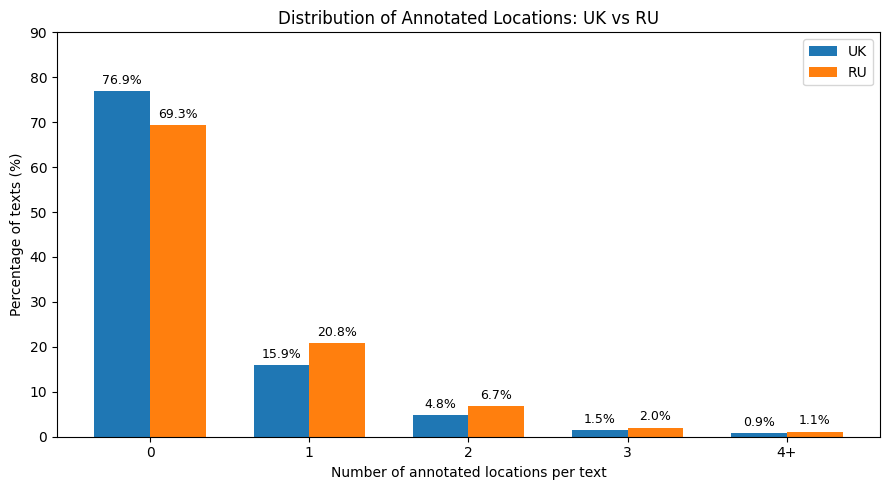

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(5)
width = 0.35

for i, (label, result) in enumerate(scans.items()):
    counts = result["loc_counts"]
    pct = pd.Series(counts).groupby(
        lambda n: min(n, 4)
    ).sum().reindex(range(5), fill_value=0)
    pct = pct / sum(counts.values()) * 100

    bars = ax.bar(x + (i - 0.5) * width, pct, width, label=label.upper())
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_xticks(x, ["0", "1", "2", "3", "4+"])
ax.set_xlabel("Number of annotated locations per text")
ax.set_ylabel("Percentage of texts (%)")
ax.set_title("Distribution of Annotated Locations: UK vs RU")
ax.legend()
ax.set_ylim(0, 90)

plt.tight_layout()
plt.show()

Most texts contain no annotated locations. Among texts with locations, single-location texts are the most common, while texts containing multiple locations are less frequent.

###  Most Frequent Locations

In [31]:
uk_locations = scans["UK"]["locations"]
ru_locations = scans["ru"]["locations"]

print("UK — top 20:")
display(pd.DataFrame(uk_locations.most_common(20), columns=["location", "count"]))

print("ru — top 20:")
display(pd.DataFrame(ru_locations.most_common(20), columns=["location", "count"]))

UK — top 20:


,location,count
0,України,24432
1,Україні,16849
2,США,8862
3,Росії,7704
4,Україна,7425
5,Києві,6541
6,Києва,4061
7,Україну,4036
8,Криму,3510
9,РФ,3349


ru — top 20:


,location,count
0,России,315084
1,США,212502
2,РФ,99327
3,Украины,86016
4,Москве,65507
5,Москвы,60854
6,Россия,41469
7,Великобритании,32841
8,Германии,26717
9,Франции,26041


The most frequent locations include countries, cities and regions.

Different grammatical forms of the same location are counted separately (e.g., "Україна", "України", "Україні"). This increases the number of unique location strings.

### Multiword Locations

In [32]:
def location_word_stats(counts):
    total = sum(counts.values())
    multiword = sum(n for loc, n in counts.items() if len(loc.split()) > 1)
    return {
        "total_spans": total,
        "unique_strings": len(counts),
        "multiword_pct": round(100 * multiword / total, 2)
    }

display(pd.DataFrame({
    "UK": location_word_stats(uk_locations),
    "ru": location_word_stats(ru_locations)
}).T)

,total_spans,unique_strings,multiword_pct
UK,345114.0,45430.0,15.39
ru,3708173.0,132589.0,11.86


Most annotated locations are single-word expressions.

# Duplicate Texts and Document Grouping

## Duplicate Texts

In [33]:
display(pd.DataFrame({label: result["duplicates"] for label, result in scans.items()}).T)

,total_rows,duplicates_within_chunks,duplicates_pct_lower_bound
UK,1010000.0,237.0,0.02
ru,8028840.0,360259.0,4.49


These are lower-bound estimates because duplicates across different chunks were not counted.

Duplicates may cause data leakage if identical texts appear in both training and validation sets. A complete duplicate check is needed before splitting the data.

The source run counted 237 within-chunk duplicates in UK (0.02%) and 360,259 in ru (4.49%). These remain lower bounds, not exact global duplicate totals.

## Document Grouping

In [34]:
doc_counts = scans["ru"]["doc_counts"]

doc_sizes = pd.Series(list(doc_counts.values()))

print("Unique documents:", len(doc_counts))
print("Missing doc_id rows:", 8_028_840 - doc_sizes.sum())
display(doc_sizes.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("texts_per_document"))

Unique documents: 739190
Missing doc_id rows: 0


,texts_per_document
count,739190.000000
mean,10.861673
std,4.362213
min,1.000000
50%,10.000000
90%,16.000000
95%,18.000000
99%,23.000000
max,686.000000


The ru dataset contains 739,190 unique documents, with an average of 10.86 texts per document.

All rows have a `doc_id`. Multiple texts from the same document may share context and information.

Document-level grouping should be considered during validation to reduce data leakage.

# Mixed alphabet?

In [39]:
LAT = re.compile(r"[A-Za-z]")
CYR = re.compile(r"[\u0400-\u04FF]")

def mixing_type(name):
    if any(LAT.search(w) and CYR.search(w) for w in name.split()):
        return "within_word"
    if LAT.search(name) and CYR.search(name):
        return "cross_word"
    return None

for label, result in scans.items():
    locations = result["locations"]
    total = sum(locations.values())
    df = pd.DataFrame([(n, c, mixing_type(n)) for n, c in locations.items() if mixing_type(n)],
        columns=["location", "count", "type"])

    summary = df.groupby("type").agg(unique=("location", "size"), occurrences=("count", "sum"))
    summary["share_of_occurrences_%"] = (summary["occurrences"] / total * 100).round(3)

    print(label)
    display(summary)
    display(df.sort_values("count", ascending=False).groupby("type").head(5))

UK


,unique,occurrences,share_of_occurrences_%
type,,,
cross_word,75,76,0.022
within_word,232,2232,0.647


,location,count,type
0,Укрaїнa,1837,within_word
4,Цікaвинки,102,within_word
24,Українi,11,within_word
18,Iвано-,8,within_word
128,Укрaїни,6,within_word
7,парку Sky Family Park,2,cross_word
193,ресторані Mcdonald's,1,cross_word
195,"ЖК ""OLYMPIC PARK""",1,cross_word
207,Парку ім. Папи Римського Івана Павла II,1,cross_word
211,заводу Leoni,1,cross_word


ru


,unique,occurrences,share_of_occurrences_%
type,,,
cross_word,3383,5062,0.137
within_word,216,308,0.008


,location,count,type
4,США (SEC),135,cross_word
92,США (FAA),65,cross_word
325,США (NASA),60,cross_word
583,США (US Geological Survey),43,cross_word
19,США (DARPA),35,cross_word
1819,Hовгородской области,11,within_word
210,Росcии,10,within_word
739,PAL-региона,8,within_word
1318,Pal-регионе,8,within_word
1355,Pal-региона,7,within_word


Mixed-alphabet locations are rare (UK 0.67%, ru 0.15% of occurrences). In UK they are mostly homoglyphs (Укрaїнa alone is ~82% of them). In ru they are mostly Latin abbreviations in parentheses (США (SEC)).

Homoglyphs should be normalized in the model input, keeping the original text for the output.

# Test Set Analysis

In [40]:
test = pd.read_csv(data_dir / "test.csv")

print("Shape:", test.shape)
print("\nMissing values:")
print(test.isna().sum())
print("\nDuplicate text_id:", test["text_id"].duplicated().sum())
print("Duplicate texts:", test["text"].duplicated().sum())
print("\nLocations:")
print(test["locations"].head(5).to_list())

Shape: (477, 3)

Missing values:
text_id      0
text         0
locations    0
dtype: int64

Duplicate text_id: 0
Duplicate texts: 0

Locations:
['[]', '[]', '[]', '[]', '[]']


In [42]:
texts = test["text"].astype(str)
patterns = {
    "URL": r"https?://|www\.",
    "hashtag": r"(?<!\w)#[\w]+",
    "mention": r"(?<!\w)@[\w]+",
    "digits": r"\d",
    "newline": r"\n",
    "CAPS": r"\b[А-ЯІЇЄҐЁЫЭЪA-Z]{2,}\b",
    "emoji": r"[\U0001F300-\U0001FAFF]"
}
style = {k: texts.str.contains(p, regex=True).mean() for k, p in patterns.items()}
display(pd.Series(style).mul(100).round(1).to_frame("% of texts"))

lengths = texts.str.len()
display(lengths.agg(["median", "max"]).to_frame("characters"))
print("p95:", round(lengths.quantile(.95)))

uk = texts.str.contains(r"[іїєґІЇЄҐ]")
ru = texts.str.contains(r"[ыэъёЫЭЪЁ]")
print("Language hints (%):", {
    "UK only": round((uk & ~ru).mean() * 100, 1),
    "RU only": round((ru & ~uk).mean() * 100, 1),
    "both": round((uk & ru).mean() * 100, 1),
    "unknown": round((~uk & ~ru).mean() * 100, 1)
})

print("Within-word mixing (%):",
      round(texts.apply(lambda s: bool(re.search(r"(?=[^\s]*[A-Za-z])(?=[^\s]*[А-Яа-яІіЇїЄєҐґЁёЫыЭэЪъ])[^\s]+", s))).mean() * 100, 1))

,% of texts
URL,4.0
hashtag,3.6
mention,3.8
digits,58.5
newline,85.1
CAPS,35.8
emoji,51.8


,characters
median,264.0
max,3682.0


p95: 1123
Language hints (%): {'UK only': np.float64(89.5), 'RU only': np.float64(6.9), 'both': np.float64(0.2), 'unknown': np.float64(3.4)}
Within-word mixing (%): 6.9


## Direct comparison with train data

In [43]:
train_samples = {}

for label, filename, frac in [
    ("UK train", "uk_geo_dataset.csv", 0.05),
    ("RU train", "ru_geo_dataset.csv", 0.006)
]:
    parts = []
    for chunk in pd.read_csv(data_dir / filename, usecols=["text"], chunksize=100_000):
        parts.append(chunk["text"].dropna().sample(frac=frac, random_state=42))
    train_samples[label] = pd.concat(parts).astype(str)

comparison = {}

for label, sample in {"Test": texts, **train_samples}.items():
    values = {key: round(sample.str.contains(pattern).mean() * 100, 1)
              for key, pattern in patterns.items()}
    values.update({
        "median length": round(sample.str.len().median()),
        "p95 length": round(sample.str.len().quantile(0.95)),
        "max length": sample.str.len().max(),
        "UK markers (%)": round(sample.str.contains(r"[іїєґІЇЄҐ]").mean() * 100, 1),
        "RU markers (%)": round(sample.str.contains(r"[ыэъёЫЭЪЁ]").mean() * 100, 1)
    })
    comparison[label] = values

display(pd.DataFrame(comparison))

,Test,UK train,RU train
URL,4.0,0.0,0.0
hashtag,3.6,0.0,0.0
mention,3.8,0.0,0.1
digits,58.5,22.2,34.5
newline,85.1,0.0,0.0
CAPS,35.8,12.3,20.0
emoji,51.8,0.0,0.0
median length,264.0,91.0,110.0
p95 length,1123.0,197.0,227.0
max length,3682.0,255.0,817.0


The test set differs strongly from the training data: it consists of long posts (median 264 chars) with emojis (52%), line breaks (85%), URLs, hashtags and mentions, none of which appear in the training sentences (median 91–110 chars). Test is also ~90% Ukrainian. A random split of train will therefore overestimate the leaderboard score, so validation should use in-domain data (labeling_sample) and training should be adapted with sentence concatenation and Telegram-style augmentation.

# Metrics Analysis

## Target Metric

The proposed metric is `normalized set-based micro F1`

For each text, true and predicted locations are normalized and converted into sets. TP, FP and FN are then aggregated across all texts.

$$
F1 = \frac{2TP}{2TP + FP + FN}
$$

Normalization includes lowercasing and removing punctuation, digits, single-character words and extra whitespace.

**This is a standard micro F1 formula with competition-specific matching rules.**


### Its pros:
- Bounded between 0 and 1, making results easy to compare.

- Balances precision and recall without being inflated by true negatives.

- Measures overall extraction quality across the entire dataset.

- Weights each counted location equally, reflecting the dataset's actual entity distribution.

- Kaggle normalization tolerates capitalization and punctuation differences.

### Its cons:

- Not differentiable, so it cannot be used directly as a training loss.

- Frequent locations and larger language groups can dominate the score, hiding poor performance on rare entities.

- Does not evaluate exact entity boundaries or character offsets.

- Gives no partial credit for incomplete location names.

- Ignores repeated occurrences of the same location within one text.



### Potential edge cases:

- Київ vs. київ! - match after normalization.

- Київ vs. Києві - mismatch because lemmatization is not applied.

- Івано-Франківськ vs. Франківськ - no partial credit.

- Duplicate locations within one text are counted only once.

## Complementary metrics

Alongside Kaggle Micro F1, we can evaluate:

- Entity-level F1 (seqeval): checks whether complete entities and their BIO boundaries are correctly predicted.

- Precision and Recall: distinguish false positives from missed locations.

- F1 by language (UK / ru): reveals performance differences hidden by global micro averaging.

## Alternative target metric

- `Per-text F1`

$$
\text{F1}_{\text{text}} = \frac{1}{N}\sum_{i=1}^{N} F1_i
$$

where $F1_i$ is the F1 score of text $i$ (it is 1 if both the prediction and the ground truth are empty).

It computes F1 separately for each text, so every text has the same weight. This matters here because the test set consists of long posts with many locations, which dominate the official micro F1. It also penalizes false positives on texts without locations. We can use it to compare models and keep the official micro F1 as the main score.

Its drawbacks: it is noisy for short texts with one location (the score is 0 or 1), and it gives no partial credit for incomplete names.